In [38]:
import sys
import os
import glob
import importlib

import tqdm

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

In [40]:
import jax
jax.config.update('jax_enable_x64', True)

import jax.random
import jax.numpy as jnp

In [41]:
import discovery as ds
import discovery.models.nanograv as ds_nanograv
import discovery.samplers.numpyro as ds_numpyro
importlib.reload(ds)
importlib.reload(ds_nanograv)
importlib.reload(ds_numpyro)
importlib.reload(ds.pulsar)
importlib.reload(ds.likelihood)
importlib.reload(ds.signals)
importlib.reload(ds.matrix)
importlib.reload(ds.prior)

<module 'discovery.prior' from '/h/mit227/discovery-ppa/src/discovery/prior.py'>

In [45]:
psr = ds.Pulsar.read_feather('/DATA/CARINA_4/mit227/subband_PA_data/J0630-2834.PA.head_derot.minusSBmean.feather', json_metadata=False)
print(psr)

<Pulsar J0630-2834: 632 res, 0 pars>


In [46]:
with np.printoptions(threshold=sys.maxsize):
    print(np.degrees(psr.residuals))
    print(np.degrees(psr.toaerrs))

[ 2.43829247e+00  2.96954383e+00  2.10544360e+00  3.34385290e+00
  7.35127219e+00  2.35993962e-01             nan -7.98350630e-01
  2.45281146e+00  1.65760764e+00  1.91088208e+00 -7.60311452e+00
             nan -7.93378758e+00  9.76545088e-01  1.11619315e+00
  1.55165683e-02  4.10223798e+00             nan  5.77687763e+00
  2.68603032e+00  2.69709071e+00  5.41966935e-01  1.38181567e+00
  2.44760398e+00  1.87310789e+00             nan  2.44493929e+00
  7.97095040e+00  3.00710402e+00  2.26085352e+00  5.24188114e-01
  1.53033778e+00 -8.21422445e-01             nan -8.35389711e+00
  9.34600627e+00  2.72324967e+00  3.68908561e+00  1.33582392e-01
  7.13016843e+00 -2.49947115e+00             nan -6.39851949e-01
  9.60548785e+00  4.50641905e+00  2.45212411e+00  4.09683928e+00
  2.20211984e+00 -1.67610774e+00             nan -8.70237445e+00
  8.32202255e+00  4.47060664e+00  3.72065583e+00  2.52064663e+00
  2.52365286e+00  3.23853074e+00             nan  2.72881617e+00
  1.28973125e+01  7.24969

In [47]:
with np.printoptions(threshold=sys.maxsize):
    print(psr.freqs)
    print(psr.subbands)

[ 813.891 1058.787 1413.82  1780.746 2106.623 2764.475 3259.243 3805.26
 1084.623 1787.854 2107.345 2765.113 3258.315 3804.586 1424.412 1790.556
 2106.536 2764.554 3256.841 3805.355  813.065 1058.641 1417.046 1780.321
 2106.756 2764.755 3258.916 3807.822  828.289 1042.908 1416.745 1779.478
 2106.756 2764.772 3259.168 3804.55   808.24  1070.511 1416.373 1779.446
 2107.275 2764.772 3258.549 3806.441  888.3   1063.578 1424.2   1777.45
 2107.275 2764.453 3258.511 3805.441  813.36  1057.735 1415.36  1780.231
 2106.59  2764.553 3258.271 3808.989  798.879 1061.958 1421.612 1781.371
 2106.59  2764.755 3258.004 3806.722  799.803 1063.142 1420.053 2107.128
 2768.845 3257.957 3806.546  807.69  1061.583 1419.203 1778.87  2106.06
 2764.755 3258.796 3806.438  804.611 1063.232 1414.318 1776.727 2107.275
  814.    1076.666 1413.825 1778.925 2107.275 2764.739 3257.835 3807.471
  820.208 1089.846 1420.287 1779.204 2107.275 2771.68  3258.272 3809.453
 1092.042 1431.154 1797.373 2106.685 2764.899 3258.925

In [48]:
obs_PA_dict = {}
for obs in psr.obsnames:
    mask = psr.obsnames == obs
    obs_sbs = psr.subbands[mask]
    obs_PAs = psr.residuals[mask]

    PA_list_for_dict = []
    i_in_orig = 0
    for sb in range(1,8+1):
        if sb in obs_sbs:
            PA_list_for_dict.append(obs_PAs[i_in_orig])
            i_in_orig += 1
        else:
            PA_list_for_dict.append(np.nan)

    obs_PA_dict[obs] = PA_list_for_dict

pd.set_option('display.max_rows', None)
df = pd.DataFrame(obs_PA_dict, index=range(1,8+1)).T
df

,1,2,3,4,5,6,7,8
uwl_181217_105935_b4,0.042556,0.051828,0.036747,0.058361,0.128304,0.004119,NaN,-0.013934
uwl_190116_090245_b4,NaN,0.042810,NaN,0.028931,0.033351,-0.132699,NaN,-0.138471
uwl_190217_064949_b4,NaN,NaN,0.017044,0.019481,0.000271,0.071598,NaN,0.100826
uwl_190315_044721_b4,0.046880,0.047073,0.009459,0.024117,0.042719,0.032692,NaN,0.042672
uwl_190505_013447_b4,0.139119,0.052484,0.039459,0.009149,0.026709,-0.014337,NaN,-0.145803
uwl_190611_235648_b4,0.163119,0.047530,0.064387,0.002331,0.124445,-0.043624,NaN,-0.011168
uwl_190705_001001_b4,0.167647,0.078652,0.042798,0.071503,0.038434,-0.029254,NaN,-0.151885
uwl_190705_212127_b4,0.145247,0.078027,0.064938,0.043994,0.044046,0.056523,NaN,0.047627
uwl_190727_195455_b4,0.225101,0.126531,0.084902,-0.008070,-0.064868,-0.042253,NaN,-0.088401
uwl_190823_182145_b4,0.178637,0.086215,0.065601,NaN,0.025749,-0.173380,NaN,-0.144727


In [49]:

pd.reset_option('display.max_rows')
        

[]

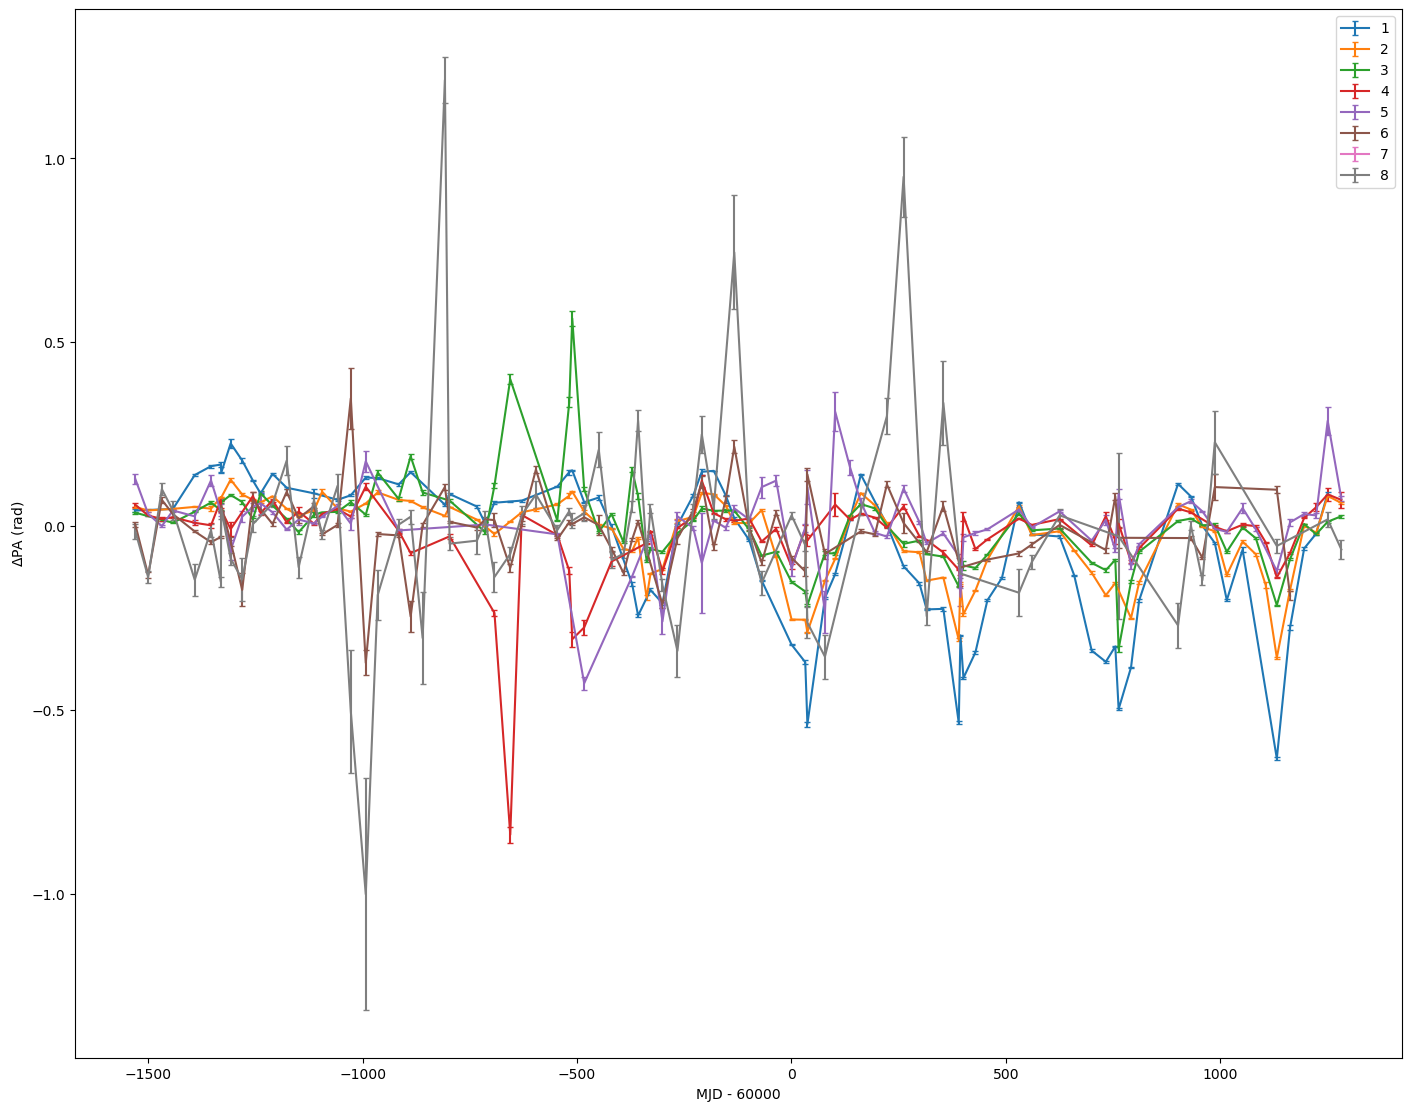

In [50]:
from astropy.time import Time

fig, ax = plt.subplots(1, 1, figsize=(14, 11), layout='constrained')

for sb in range(1,8+1):
    mask = psr.subbands == sb
    t = Time(psr.toas[mask], format='unix', scale='utc')
    ax.errorbar(t.mjd-60000, 
                # np.degrees(
                    psr.residuals[mask],
                    # ), 
                # np.degrees(
                    psr.toaerrs[mask],
                    # ), 
                capsize=2.5, label=sb)

ax.set_xlabel('MJD - 60000')
ax.set_ylabel('$\\Delta$PA (rad)')
ax.legend()
plt.plot()

#### Measurement noise only, no backends

In [12]:
m = ds.PulsarLikelihood([psr.residuals,#np.nan_to_num(psr.residuals, nan=0.0),
                         ds.makenoise_measurement_simple(psr)])

In [13]:
m.logL.params

['J0630-2834_efac', 'J0630-2834_log10_t2equad']

In [14]:
p0 = ds.sample_uniform(m.logL.params)
print(p0)
print(m.logL(p0))

{'J0630-2834_efac': 1.0466339103375875, 'J0630-2834_log10_t2equad': -3.3354887246283873}
nan


#### Add ECORR noise (GP), free params, no backends

In [15]:
m_ecorr = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement_simple(psr),
                         ds.makegp_ecorr_simple(psr)])
print(m_ecorr.logL.params)

['J0630-2834_efac', 'J0630-2834_log10_ecorr', 'J0630-2834_log10_t2equad']


In [16]:
p0 = ds.sample_uniform(m_ecorr.logL.params)
print(p0)
print(f'w/  ECORR: {m_ecorr.logL(p0)}')
print(f'w/o ECORR: {m.logL(p0)}')

{'J0630-2834_efac': 2.1703286864466556, 'J0630-2834_log10_ecorr': -1.5569717219589467, 'J0630-2834_log10_t2equad': -2.248559013400474}
w/  ECORR: nan
w/o ECORR: nan


#### Add RM noise

In [17]:
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement_simple(psr),
                         ds.makegp_ecorr_simple(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
print(m_RM.logL.params)

['J0630-2834_efac', 'J0630-2834_log10_ecorr', 'J0630-2834_log10_t2equad', 'J0630-2834_rmgp_gamma', 'J0630-2834_rmgp_log10_A']


In [18]:
p0 = ds.sample_uniform(m_RM.logL.params)
print(p0)
print(f'Noise:          {m.logL(p0):e}')
print(f'Noise+ECORR:    {m_ecorr.logL(p0):e}')
print(f'Noise+ECORR+RM: {m_RM.logL(p0):e}')

{'J0630-2834_efac': 2.680318951077016, 'J0630-2834_log10_ecorr': -2.574829523795989, 'J0630-2834_log10_t2equad': -3.4390563799015847, 'J0630-2834_rmgp_gamma': 1.9764935704358721, 'J0630-2834_rmgp_log10_A': -8.629354067502465}
Noise:          nan
Noise+ECORR:    nan
Noise+ECORR+RM: nan


[]

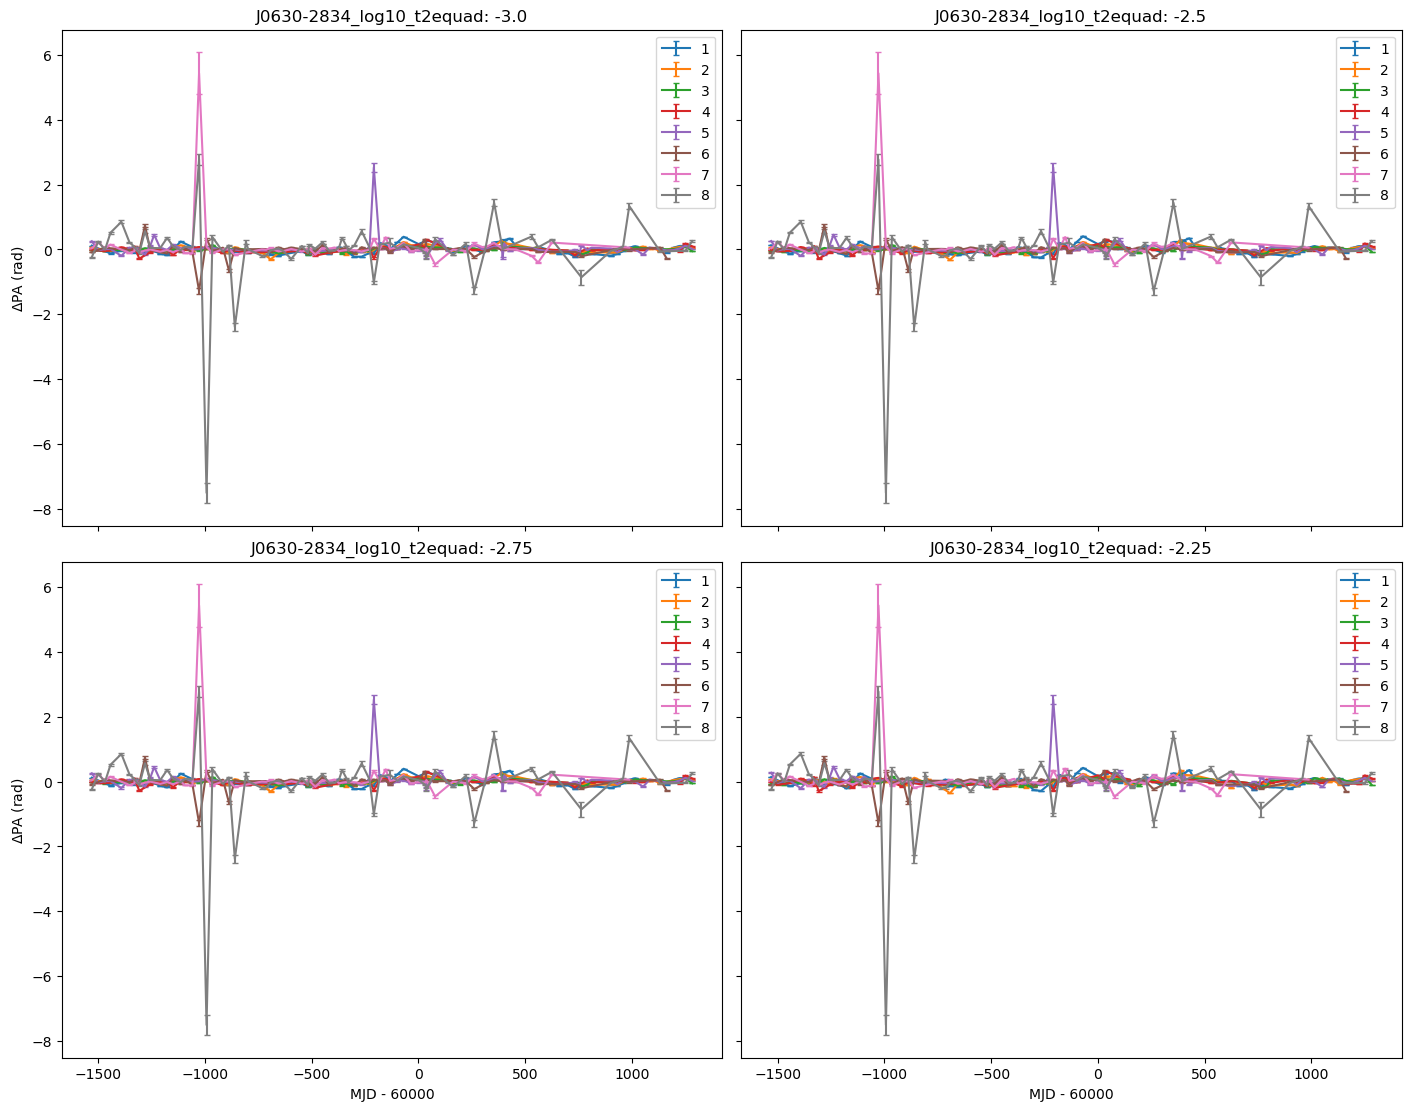

In [21]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # fix parameters to reasonable value
        params = {
            'J0630-2834_efac':10.000,
            'J0630-2834_log10_ecorr':-5.000,
            'J0630-2834_log10_t2equad':-3.000+(i+2*j)/4,
            'J0630-2834_rmgp_gamma':0.986,
            'J0630-2834_rmgp_log10_A':-8.121
            }

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42)#+i+2*j)
        key, res = m_RM.sample(key, params)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.set_title(f'J0630-2834_log10_t2equad: {params['J0630-2834_log10_t2equad']}')
        ax.legend()

plt.plot()

#### Add achromatic red noise

In [22]:
m_red = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement_simple(psr),
                         ds.makegp_ecorr_simple(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp'),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, name='rednoise')
                         ])
print(m_red.logL.params)

['J0630-2834_efac', 'J0630-2834_log10_ecorr', 'J0630-2834_log10_t2equad', 'J0630-2834_rednoise_gamma', 'J0630-2834_rednoise_log10_A', 'J0630-2834_rmgp_gamma', 'J0630-2834_rmgp_log10_A']


[]

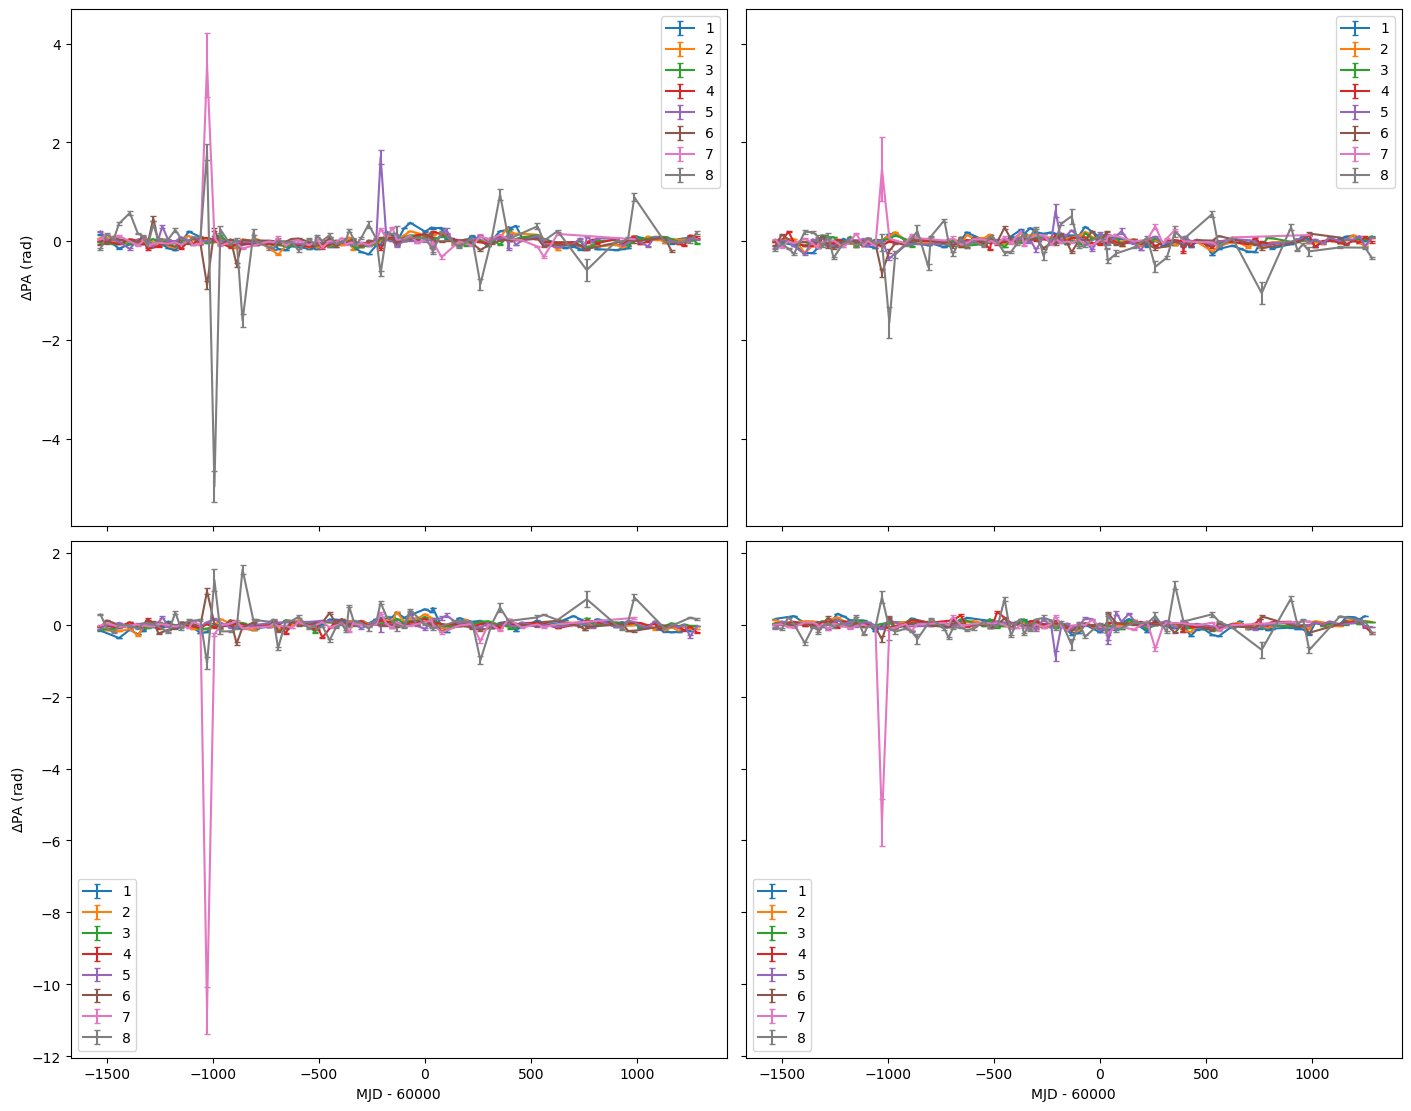

In [24]:
sampler = m_red.sample

fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # fix parameters to reasonable value
        # params = {
        #     'J0835-4510_efac':4.0,#7.405,
        #     'J0835-4510_log10_ecorr':-2.006,
        #     'J0835-4510_log10_t2equad':-2.287,
        #     'J0835-4510_rednoise_gamma':2.0, 
        #     'J0835-4510_rednoise_log10_A':-9,
        #     'J0835-4510_rmgp_gamma':1.118,
        #     'J0835-4510_rmgp_log10_A':-8.140
        #     }
        params = {
        'J0630-2834_efac':6.635,
        'J0630-2834_log10_ecorr':-1.603,
        'J0630-2834_log10_t2equad':-2.252,
        'J0630-2834_rednoise_gamma':1.403,
        'J0630-2834_rednoise_log10_A':-9.615,
        'J0630-2834_rmgp_gamma':1.192,
        'J0630-2834_rmgp_log10_A':-8.135
        }

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = sampler(key, params)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

In [25]:
from discovery import prior
from discovery.params import Params, make_layout

import numpyro
from numpyro import infer, distributions as dist

In [26]:
logL = m_RM.logL

# static layout shared by every Params built inside the model
layout, size = make_layout(logL.params)

# flat uniform bounds, one entry per (scalar) parameter
bounds = [prior.getprior_uniform(p) for p in logL.params]
print(bounds)
lo = jnp.array([b[0] for b in bounds])
hi = jnp.array([b[1] for b in bounds])

def numpyro_model():
    raw = numpyro.sample('raw', dist.Uniform(lo, hi))   # one (P,) array site
    numpyro.factor('logl', logL(Params(raw, layout)))

[[0.1, 10], [-3, -1], [-3.5, -1.5], [0, 2], [-9, -7]]


In [27]:
sampler = infer.MCMC(infer.NUTS(numpyro_model),
                     num_warmup=100, num_samples=100)
sampler.run(jax.random.PRNGKey(42))

RuntimeError: Cannot find valid initial parameters. Please check your model again.

In [30]:
raw_samples = sampler.get_samples()['raw']
# print(raw_samples)

p_fit = {}
for i, name in enumerate(logL.params):
    col = raw_samples[:, i]
    print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  bounds={bounds[i]}')
    p_fit[name] = col.mean()

print(p_fit)
print(f'{logL(p_fit):e}')

J0738-4042_efac                mean=+9.872  std=0.104  bounds=[0.1, 10]
J0738-4042_log10_ecorr         mean=-1.480  std=0.036  bounds=[-3, -1]
J0738-4042_log10_t2equad       mean=-2.387  std=0.015  bounds=[-3.5, -1.5]
J0738-4042_rednoise_gamma      mean=+3.267  std=0.592  bounds=[0, 4]
J0738-4042_rednoise_log10_A    mean=-9.174  std=0.258  bounds=[-10, -8]
J0738-4042_rmgp_gamma          mean=+1.151  std=0.253  bounds=[0, 2]
J0738-4042_rmgp_log10_A        mean=-8.098  std=0.048  bounds=[-9, -7]
{'J0738-4042_efac': Array(9.8719141, dtype=float64), 'J0738-4042_log10_ecorr': Array(-1.480073, dtype=float64), 'J0738-4042_log10_t2equad': Array(-2.38749469, dtype=float64), 'J0738-4042_rednoise_gamma': Array(3.2668505, dtype=float64), 'J0738-4042_rednoise_log10_A': Array(-9.17446606, dtype=float64), 'J0738-4042_rmgp_gamma': Array(1.15145368, dtype=float64), 'J0738-4042_rmgp_log10_A': Array(-8.09795545, dtype=float64)}
2.154003e+03


<class 'jaxlib._jax.ArrayImpl'>


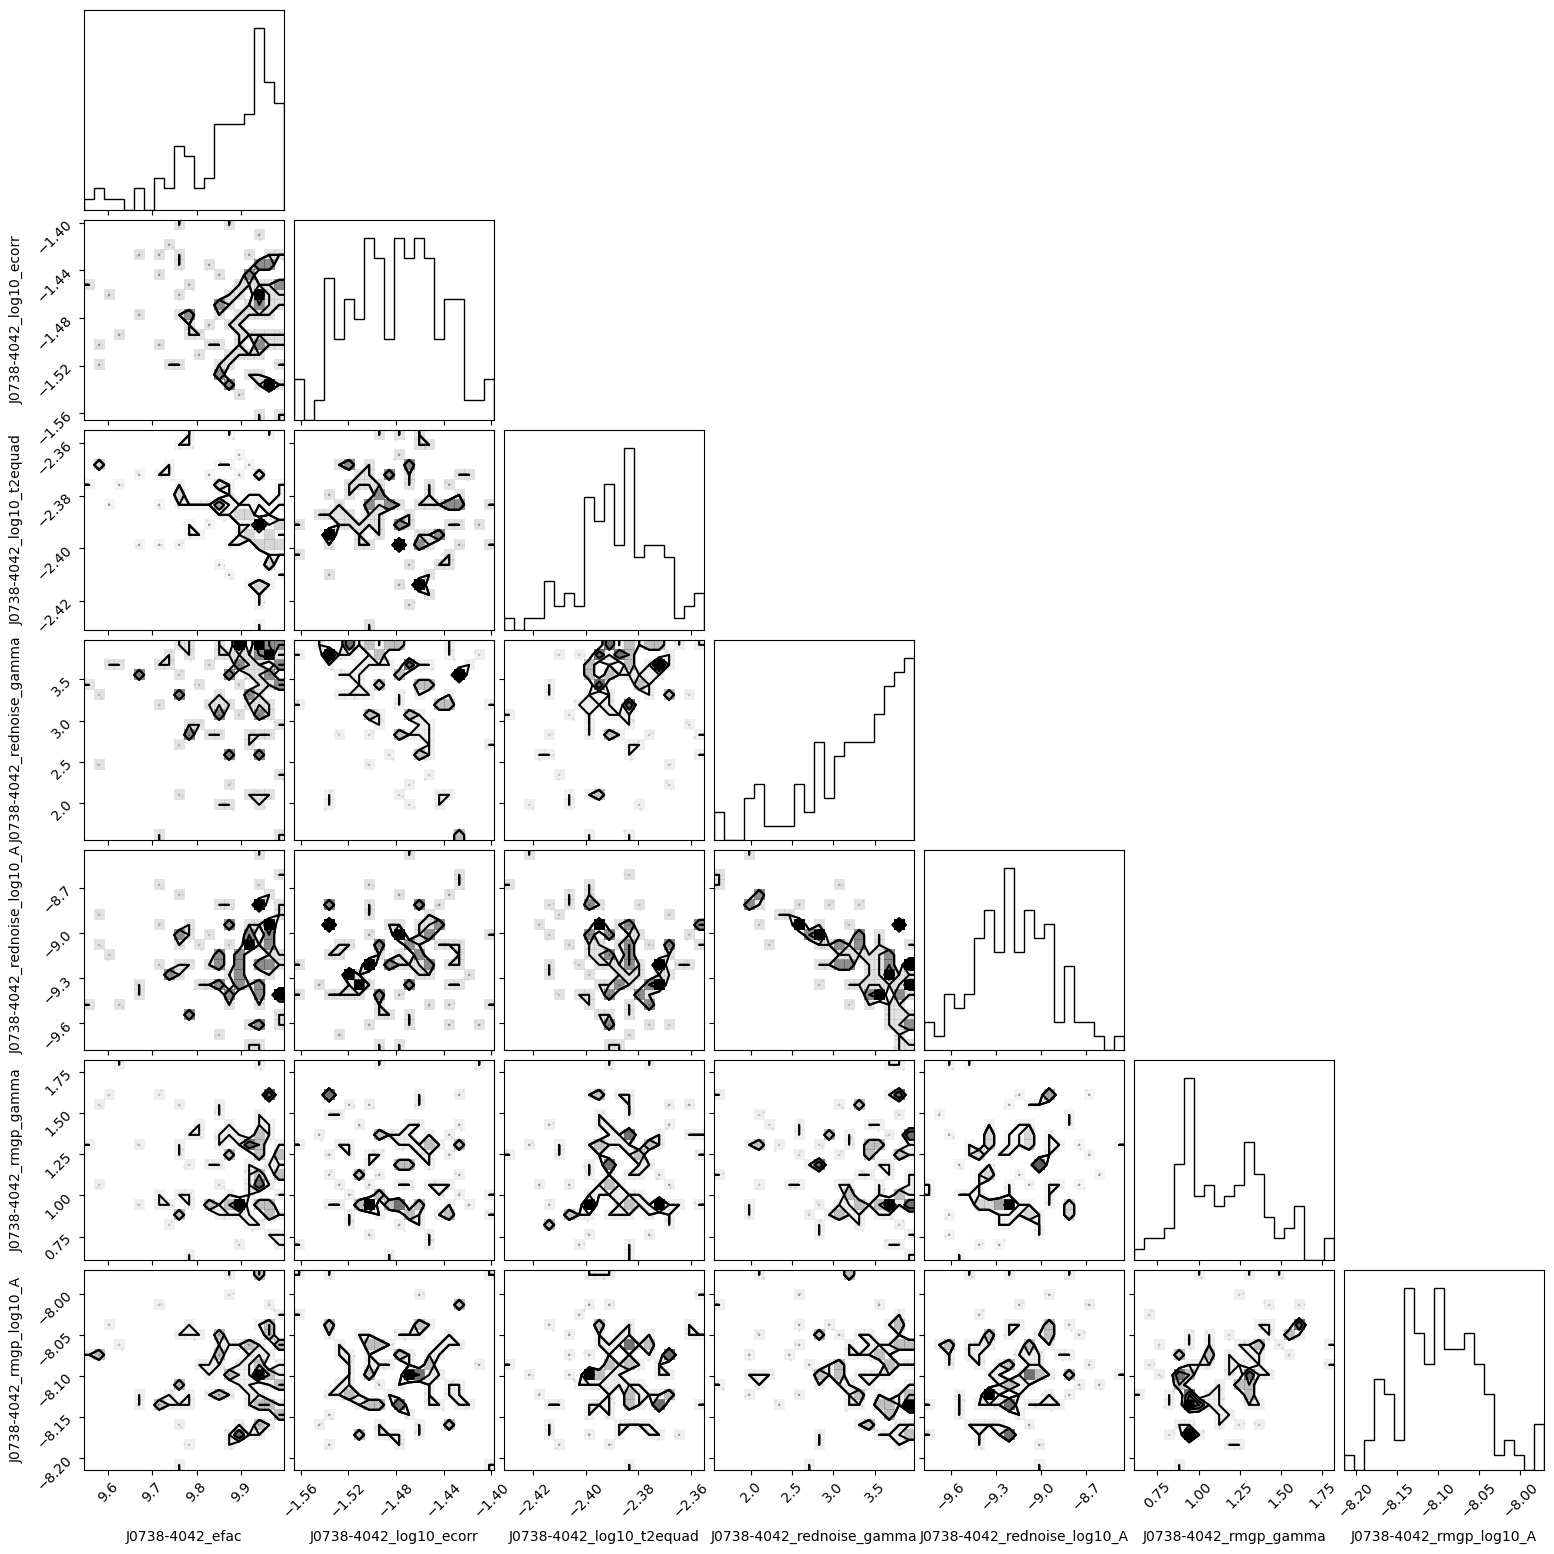

In [31]:
import corner 
figure = corner.corner(
    np.array(raw_samples),
    labels=logL.params
    )
print(type(raw_samples))

[]

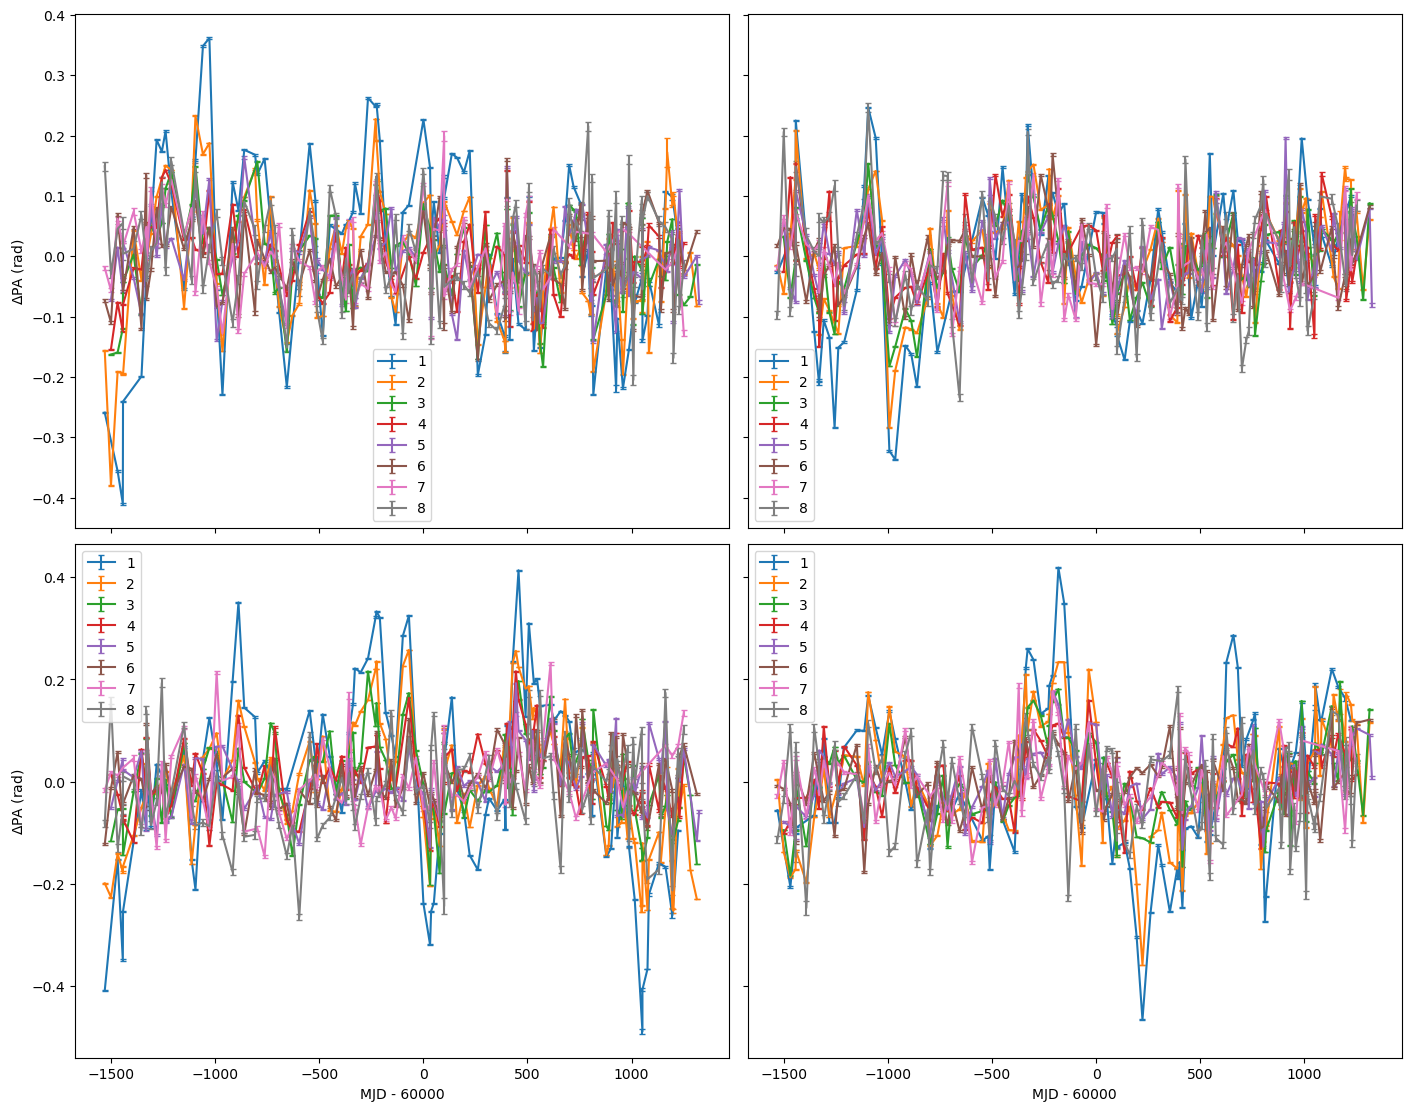

In [32]:
# sampler = m_red.sample

fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_red.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()